# GIAI ĐOẠN 3: XÂY DỰNG MÔ HÌNH MACHINE LEARNING (RANDOM FOREST)
**Dữ liệu đầu vào:** `BankChurners_clean.csv` (10.127 khách hàng × 21 cột)  
**Biến mục tiêu:** `Attrition_Flag` (`0` = Khách ở lại, `1` = Khách rời bỏ)

**Mục tiêu của Notebook:**
1. Chọn lọc **9 biến số hành vi & tài chính** cốt lõi từ bước EDA để đưa vào mô hình Học máy.
2. Huấn luyện mô hình **Random Forest** có cân bằng trọng số để xử lý dữ liệu mất cân bằng (83,93% ở lại - 16,07% rời bỏ).
3. Đánh giá hiệu suất mô hình qua **Recall**, **F1-Score**, xếp hạng mức độ quan trọng của 9 biến và trích xuất danh sách khách hàng cần chăm sóc khẩn cấp.

## 1. Đọc dữ liệu và Chọn lọc đặc trưng (Feature Selection)

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

sns.set_theme(style="whitegrid")
plt.rcParams["text.parse_math"] = False

df = pd.read_csv("BankChurners_clean.csv")

cot_chu = ["Gender", "Education_Level", "Marital_Status", "Income_Category", "Card_Category"]
cot_nhankhau_so = ["Customer_Age", "Dependent_count", "Months_on_book"]
cot_loai_bo = ["CLIENTNUM", "Attrition_Flag", "Avg_Open_To_Buy", "Credit_Limit"] + cot_chu + cot_nhankhau_so

X = df.drop(columns=cot_loai_bo)
y = df["Attrition_Flag"]

print("Số biến đầu vào giữ lại:", X.shape[1])
print("Danh sách 9 biến:", list(X.columns))

Số biến đầu vào giữ lại: 9
Danh sách 9 biến: ['Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Total_Revolving_Bal', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']


## 2. Chia dữ liệu Train/Test (80/20) và Huấn luyện mô hình Random Forest

In [2]:
# 1. Chia tập Train (80%) và Test (20%), giữ nguyên tỷ lệ 16.07% rời bỏ (stratify=y)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Số khách tập Train:", len(X_train), "| Tỷ lệ rời bỏ (%):", round(y_train.mean() * 100, 2))
print("Số khách tập Test :", len(X_test),  "| Tỷ lệ rời bỏ (%):", round(y_test.mean() * 100, 2))

# 2. Khởi tạo và huấn luyện mô hình Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,          # Sử dụng 200 cây quyết định độc lập
    max_depth=8,               # Giới hạn độ sâu tối đa 8 tầng để tránh học vẹt (overfitting)
    class_weight="balanced",   # Cân bằng trọng số phạt gấp 5.22 lần cho nhóm Rời bỏ
    random_state=42
)

rf_model.fit(X_train, y_train)
print("Đã huấn luyện xong mô hình Random Forest!")

Số khách tập Train: 8101 | Tỷ lệ rời bỏ (%): 16.07
Số khách tập Test : 2026 | Tỷ lệ rời bỏ (%): 16.04
Đã huấn luyện xong mô hình Random Forest!


## 3. Đánh giá hiệu suất mô hình (Confusion Matrix, Recall & F1-Score)

Accuracy  (Độ chính xác tổng thể) : 93.68 %
Precision (Độ chuẩn xác cảnh báo) : 74.81 %
Recall    (Tỷ lệ bắt đúng rời bỏ) : 91.38 %
F1-Score  (Điểm cân bằng tổng hợp): 82.27 %


Text(44.01917860243056, 0.5, 'Thực tế')

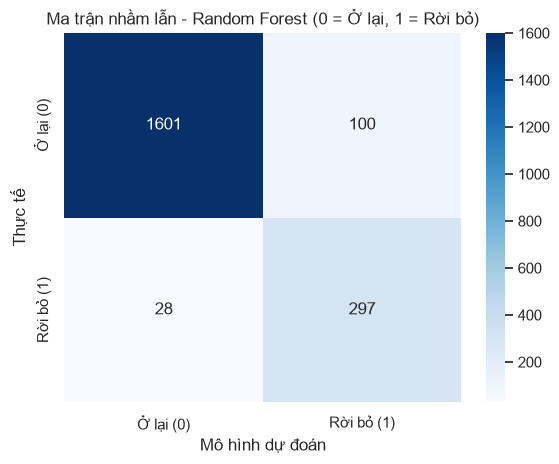

In [3]:
# Dự đoán nhãn (0/1) trên tập Test (2.026 khách hàng)
y_pred = rf_model.predict(X_test)

# In các chỉ số đánh giá trọng tâm cho nhóm Rời bỏ (Class 1)
print("Accuracy  (Độ chính xác tổng thể) :", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Precision (Độ chuẩn xác cảnh báo) :", round(precision_score(y_test, y_pred) * 100, 2), "%")
print("Recall    (Tỷ lệ bắt đúng rời bỏ) :", round(recall_score(y_test, y_pred) * 100, 2), "%")
print("F1-Score  (Điểm cân bằng tổng hợp):", round(f1_score(y_test, y_pred) * 100, 2), "%")
# Vẽ Ma trận nhầm lẫn (Confusion Matrix)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Ở lại (0)", "Rời bỏ (1)"],
    yticklabels=["Ở lại (0)", "Rời bỏ (1)"]
)
plt.title("Ma trận nhầm lẫn - Random Forest (0 = Ở lại, 1 = Rời bỏ)")
plt.xlabel("Mô hình dự đoán")
plt.ylabel("Thực tế")

**Nhận xét kết quả đánh giá độ chính xác của mô hình:**

- **Độ chính xác tổng thể (Accuracy) đạt 93,68%:** Trên toàn bộ tập kiểm thử gồm 2.026 khách hàng, mô hình dự đoán đúng **1.898 trường hợp** (gồm **1.601** khách ở lại và **297** khách rời bỏ), chỉ dự đoán sai **128 trường hợp**.
- **Tỷ lệ bắt đúng khách rời bỏ (Recall) đạt 91,38%:** Trong tổng số **325 khách hàng** thực tế rời bỏ , mô hình phát hiện chính xác **297 người** và chỉ bỏ sót **28 người**. Điều này cho thấy mô hình nhận diện rất tốt nhóm khách hàng có nguy cơ hủy thẻ.
- **Độ chuẩn xác cảnh báo (Precision) đạt 74,81%:** Trong tổng số **397 khách hàng** bị mô hình dự đoán rời bỏ , có **297 người** thực sự rời bỏ và **100 người** thực tế vẫn đang ở lại.
- **Điểm cân bằng tổng hợp (F1-Score) đạt 82,27%:** Chỉ số này ở mức cao, cho thấy mô hình hoạt động ổn định, vừa bắt được phần lớn khách hàng sắp rời bỏ vừa kiểm soát tốt số lượng cảnh báo nhầm.

## 4. Xếp hạng mức độ quan trọng của 9 biến (Feature Importance)

Text(0, 0.5, 'Biến đặc trưng')

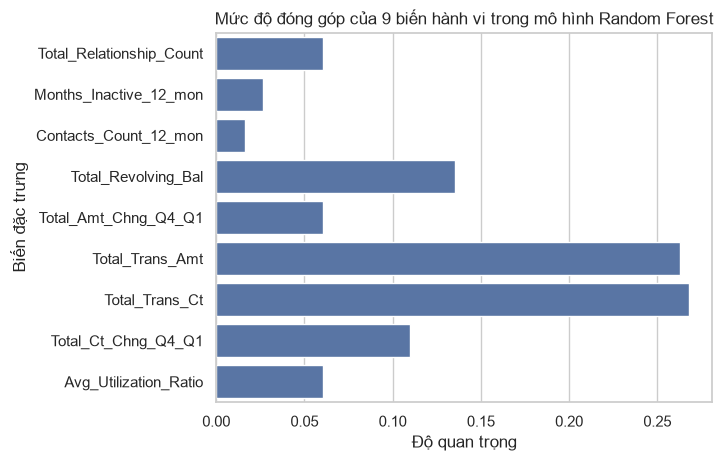

In [4]:
# Lấy điểm quan trọng của 9 biến từ mô hình Random Forest và sắp xếp giảm dần
bang_imp = pd.DataFrame({
    "Bien_so": X.columns,
    "Do_quan_trong": rf_model.feature_importances_
})

# Vẽ biểu đồ cột ngang xếp hạng độ quan trọng
sns.barplot(data=bang_imp, x="Do_quan_trong", y="Bien_so")
plt.title("Mức độ đóng góp của 9 biến hành vi trong mô hình Random Forest")
plt.xlabel("Độ quan trọng")
plt.ylabel("Biến đặc trưng")

## 5. Ứng dụng thực tế: Trích xuất danh sách cảnh báo sớm (Watchlist)

In [5]:
# Chọn mã khách hàng và các thuộc tính hành vi cốt lõi để CSKH nắm rõ nguyên nhân rủi ro
cot_watchlist = [
    "CLIENTNUM", "Total_Trans_Ct", "Total_Trans_Amt",
    "Total_Ct_Chng_Q4_Q1", "Total_Revolving_Bal",
    "Contacts_Count_12_mon", "Months_Inactive_12_mon", "Total_Relationship_Count"
]

# Lọc khách thực tế chưa rời bỏ (y_test == 0) nhưng bị dự đoán rời bỏ (y_pred == 1)
watchlist = df.loc[X_test.index, cot_watchlist][(y_test == 0) & (y_pred == 1)]

# Sắp xếp ưu tiên khách có số lần quẹt thẻ thấp nhất lên đầu để gọi chăm sóc trước
watchlist = watchlist.sort_values(by="Total_Trans_Ct", ascending=True)

print("Số lượng khách hàng cần CSKH liên hệ giữ chân ngay:", len(watchlist), "khách hàng")
display(watchlist.head(10))

Số lượng khách hàng cần CSKH liên hệ giữ chân ngay: 100 khách hàng


,CLIENTNUM,Total_Trans_Ct,Total_Trans_Amt,Total_Ct_Chng_Q4_Q1,Total_Revolving_Bal,Contacts_Count_12_mon,Months_Inactive_12_mon,Total_Relationship_Count
83,755420433,20,1068,0.818,1417,3,3,2
3167,772000533,23,1809,0.278,1113,2,3,4
886,708655983,24,1353,0.263,0,2,3,3
3520,716944983,27,1658,0.500,2517,4,3,4
558,720179883,27,1179,0.688,0,1,3,3
544,709103358,27,1128,0.929,0,3,3,6
636,713580633,27,1260,0.688,0,3,2,6
370,719091333,27,1102,0.286,793,2,3,3
1082,715511658,27,1431,0.688,0,4,1,3
40,827111283,28,1109,0.474,578,2,2,2
